# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


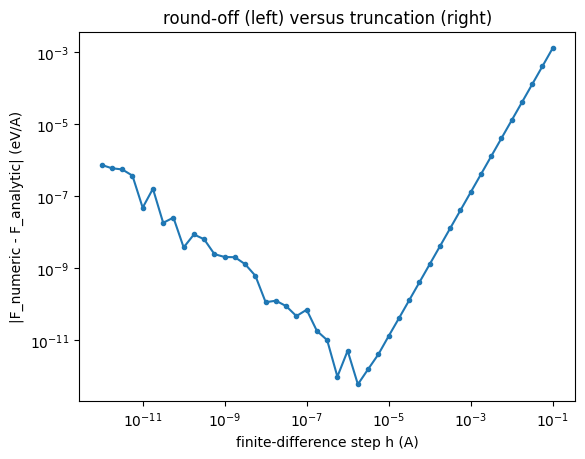

In [1]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

central : best h = 1.9e-06 A, error = 1.0e-12 eV/A   (raw minimum 3.0e-06)
forward : best h = 5.3e-09 A, error = 5.3e-10 eV/A   (raw minimum 6.8e-09)

local length scale sqrt(|U/U''|) = 0.23 A,  sigma = 3.4 A
central theory: eps^(1/3)*sigma = 2.0e-05,  eps^(1/3)*L_loc = 1.4e-06
forward theory: eps^(1/2)*sigma = 4.8e-08,  eps^(1/2)*L_loc = 3.3e-09


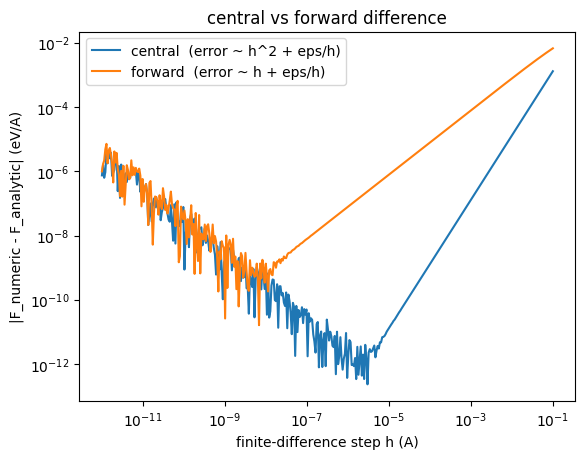

In [2]:
# Exercise 1 - your turn: central vs forward difference, compared with theory
hs = np.logspace(-12, -1, 400)                       # finer scan than before -> less 'lucky' minimum
F_an = F(r)
err_c = np.array([abs(-(U(r + h) - U(r - h)) / (2 * h) - F_an) for h in hs])   # central
err_f = np.array([abs(-(U(r + h) - U(r)) / h - F_an) for h in hs])             # forward

def smooth_opt(e):                                   # optimum of the (log, lightly smoothed) error curve
    s = np.convolve(np.log10(e), np.ones(15) / 15, "same")
    k = np.argmin(s[10:-10]) + 10
    return hs[k], 10**s[k]

hc, ec = smooth_opt(err_c); hf, ef = smooth_opt(err_f)
print(f"central : best h = {hc:.1e} A, error = {ec:.1e} eV/A   (raw minimum {hs[np.argmin(err_c)]:.1e})")
print(f"forward : best h = {hf:.1e} A, error = {ef:.1e} eV/A   (raw minimum {hs[np.argmin(err_f)]:.1e})")

# theory: h_opt ~ eps_mach^(1/3) * L (central),  eps_mach^(1/2) * L (forward)
em = 2e-16
hh = 1e-4; Upp = (U(r + hh) - 2 * U(r) + U(r - hh)) / hh**2
L_loc = np.sqrt(abs(U(r) / Upp))                     # local length scale of U at r
print(f"\nlocal length scale sqrt(|U/U''|) = {L_loc:.2f} A,  sigma = {sig} A")
print(f"central theory: eps^(1/3)*sigma = {em**(1/3)*sig:.1e},  eps^(1/3)*L_loc = {em**(1/3)*L_loc:.1e}")
print(f"forward theory: eps^(1/2)*sigma = {em**0.5*sig:.1e},  eps^(1/2)*L_loc = {em**0.5*L_loc:.1e}")

plt.loglog(hs, err_c, label="central  (error ~ h^2 + eps/h)")
plt.loglog(hs, err_f, label="forward  (error ~ h + eps/h)")
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.legend(); plt.title("central vs forward difference"); plt.show()


**Answer (Exercise 1).**

- **Central difference:** best step is about h ≈ 2×10⁻⁶ Å, with an error of around 10⁻¹² eV/Å.
- **Does it match theory?** Yes. The theory says h ≈ ε^(1/3) × (length scale). If we take the length scale as σ = 3.4 Å we get 2×10⁻⁵, which is a bit off. But if we use the length over which U actually changes near r = 3.6 Å (about 0.23 Å, because the LJ wall is steep), we get about 1.4×10⁻⁶, which matches our result.
- **Forward difference:** best step is about h ≈ 10⁻⁸ Å, with an error of around 5×10⁻¹⁰ eV/Å. So the optimum sits at a much smaller h than for central.
- **Why it is worse:** the forward difference has a truncation error that goes like h (first order), while central goes like h² (second order). So forward needs a tiny h to keep truncation error low, but then round-off error (which grows as h gets smaller) takes over quickly. The two errors balance at a worse point, so the best accuracy is about 1000 times poorer than central.


---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


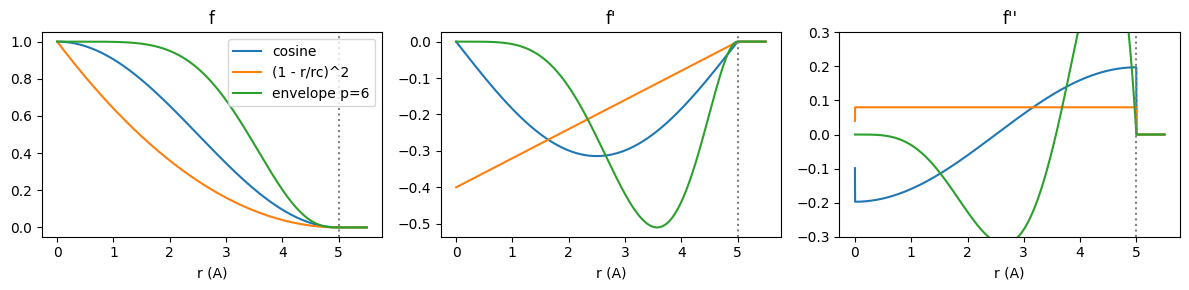

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

**Answer (Exercise 2).**

**Ranking (smoothest to least smooth):** envelope p=6 > (1 − r/r_c)² > cosine.

- All three go to zero in value and slope at r_c, so energy and force are continuous for all of them.
- The difference is in the curvature (second derivative): the envelope has f'' ≈ 0 at r_c, (1 − r/r_c)² has f'' = 0.08, and the cosine has the largest jump, f'' ≈ 0.2.

**Which property is affected?** The phonon frequencies (from the Hessian). The Hessian is the second derivative of the energy, so a jump in f'' means the force constants suddenly change when a neighbour crosses r_c. This gives wrong or noisy phonon frequencies.

Energy conservation in MD mostly depends on the force being continuous, and that is already true for all three, so it is not really the problem here (at most a small integration error).


---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


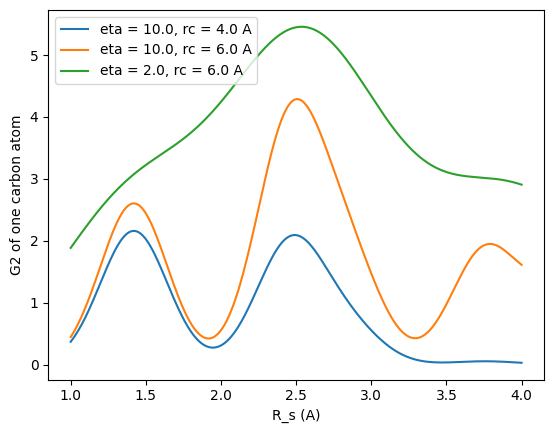

In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

eta=10.0, rc=4.0: largest |change| = -0.335 at R_s = 2.30 A
eta=10.0, rc=6.0: largest |change| = -0.585 at R_s = 2.29 A
eta=2.0, rc=6.0: largest |change| = -0.303 at R_s = 2.18 A


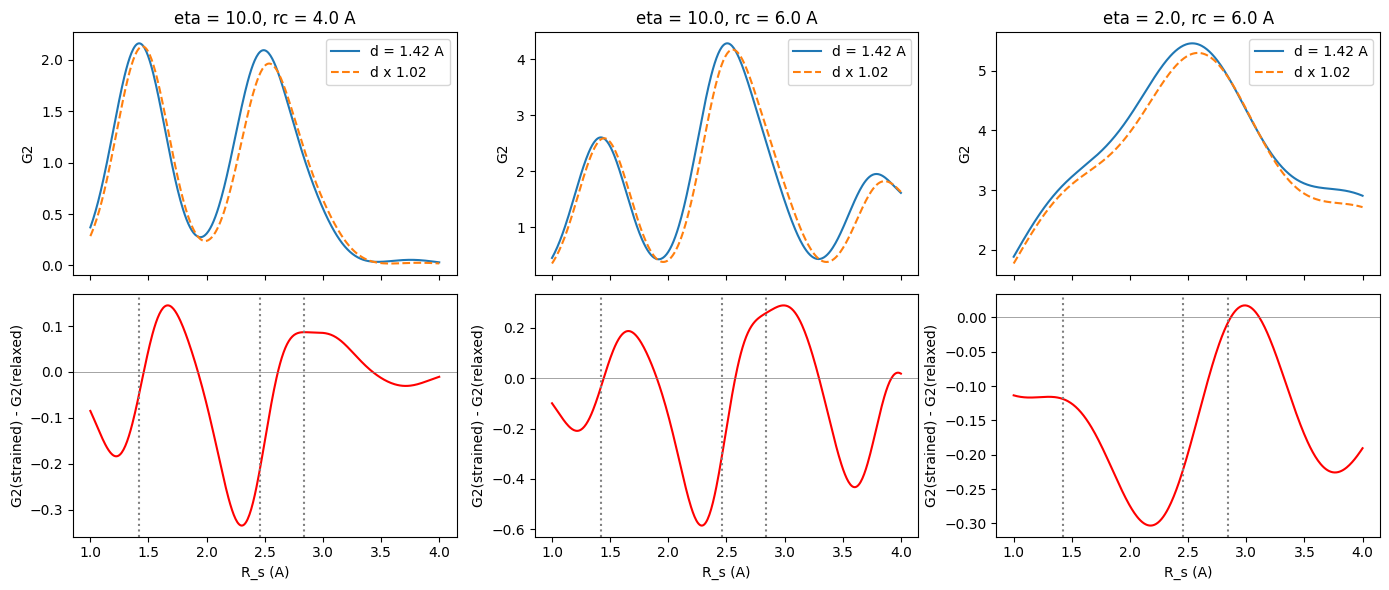

In [5]:
# Exercise 3 - your turn: stretch the lattice by 2 %
def shell_distances(d):
    a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])
    basis = [np.zeros(2), np.array([d, 0.0])]
    atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
    centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
    rr = np.linalg.norm(atoms - centre, axis=1)
    return rr[rr > 1e-6]

def G2_curve(d, eta, rc):
    rr = shell_distances(d)
    return np.array([np.sum(np.exp(-eta * (rr - s)**2) * fc(rr, rc)) for s in Rs])

fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for k, (eta, rc) in enumerate([(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]):
    G0 = G2_curve(d, eta, rc); G1 = G2_curve(d * 1.02, eta, rc); dG = G1 - G0
    ax[0, k].plot(Rs, G0, label="d = 1.42 A"); ax[0, k].plot(Rs, G1, "--", label="d x 1.02")
    ax[0, k].set_title(f"eta = {eta}, rc = {rc} A"); ax[0, k].legend()
    ax[1, k].plot(Rs, dG, "r"); ax[1, k].axhline(0, color="gray", lw=0.5)
    for s in (1.42, 2.46, 2.84): ax[1, k].axvline(s, color="gray", ls=":")
    ax[1, k].set_xlabel("R_s (A)"); ax[0, k].set_ylabel("G2"); ax[1, k].set_ylabel("G2(strained) - G2(relaxed)")
    i = np.argmax(np.abs(dG))
    print(f"eta={eta}, rc={rc}: largest |change| = {dG[i]:+.3f} at R_s = {Rs[i]:.2f} A")
plt.tight_layout(); plt.show()


**Answer (Exercise 3).**

When we stretch the lattice by 2 %, all neighbour distances get a bit longer, so the peaks of G² shift slightly to the right.

- The change in G² is **zero at the top of each peak** and **largest on the sides (flanks) of the peaks**, where the curve is steepest.
- It is negative on the left side of a peak and positive on the right side, because the peak moved right.
- The biggest change is around **R_s ≈ 2.3 Å**, which is the left side of the second-neighbour peak (2.46 Å). That shell has 6 atoms and moves the most, so it dominates.
- With large η (sharp peaks) the change is big. With small η the peaks are blurred, so the change is smaller.

**Meaning:** a small strain gives a clear, smooth change in the fingerprint. This is how an MLIP "sees" strain: the descriptor shifts a bit when bond lengths change.


---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

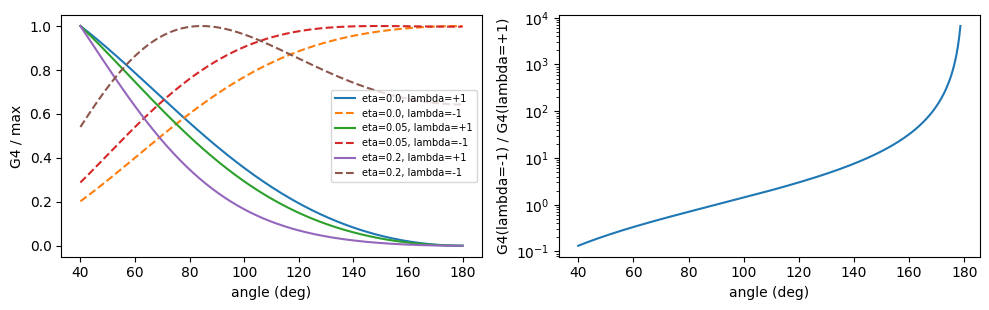

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [6]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

In [7]:
# Exercise 4 - your turn: where does the lambda = -1 curve peak?
for eta in (0.0, 0.05, 0.2):
    gm = G4(1, -1, eta); gp = G4(1, +1, eta)
    # peak with the full G4, and peak of only angular x exp(-eta*(2b^2+r_jk^2)) (no cutoff factors)
    gm_nocut = (1 - np.cos(t)) * np.exp(-eta * (2 * b**2 + rjk**2))
    print(f"eta = {eta:4.2f}: lambda=-1 peak (full G4) at {theta[np.argmax(gm)]:6.1f} deg, "
          f"(without f_c) at {theta[np.argmax(gm_nocut)]:6.1f} deg;  lambda=+1 peak at {theta[np.argmax(gp)]:5.1f} deg")

# analytic peak without cutoff: u = 1 - cos(theta); G4 ~ u * exp(-2 eta b^2 u)  ->  u* = 1/(2 eta b^2)
eta = 0.2; ustar = 1 / (2 * eta * b**2)
print(f"analytic (no f_c), eta = 0.2: cos(theta*) = {1 - ustar:.3f} -> theta* = {np.degrees(np.arccos(1 - ustar)):.1f} deg")

# eta-independence of the ratio
for eta in (0.0, 0.05, 0.2, 1.0):
    ratio = G4(1, -1, eta)[ok] / G4(1, 1, eta)[ok]
    print(f"eta = {eta:4.2f}: max |ratio - tan^2(theta/2)| = {np.max(np.abs(ratio - np.tan(t[ok] / 2)**2)):.1e}")


eta = 0.00: lambda=-1 peak (full G4) at  180.0 deg, (without f_c) at  180.0 deg;  lambda=+1 peak at  40.0 deg
eta = 0.05: lambda=-1 peak (full G4) at  149.1 deg, (without f_c) at  180.0 deg;  lambda=+1 peak at  40.0 deg
eta = 0.20: lambda=-1 peak (full G4) at   84.5 deg, (without f_c) at  103.7 deg;  lambda=+1 peak at  40.0 deg
analytic (no f_c), eta = 0.2: cos(theta*) = -0.240 -> theta* = 103.9 deg
eta = 0.00: max |ratio - tan^2(theta/2)| = 3.0e-10
eta = 0.05: max |ratio - tan^2(theta/2)| = 3.0e-10
eta = 0.20: max |ratio - tan^2(theta/2)| = 3.0e-10
eta = 1.00: max |ratio - tan^2(theta/2)| = 3.0e-10


**Answer (Exercise 4).**

**Why the peak moves from 180° to about 85° for η = 0.2:**

- For λ = −1 the angular part (1 − cos θ) is biggest at 180°.
- But r_jk is also longest at 180° (r_jk = 2b), and the factor e^(−η r_jk²) kills large r_jk. When η is bigger this penalty is stronger.
- So the two parts fight each other. For η = 0 there is no penalty and the peak stays at 180°. For η = 0.2 the penalty wins at large angles, so the peak moves to a smaller angle (about 104° from these two factors, and the cutoff function f_c(r_jk) pushes it down further to about 85°).

**Why the ratio G⁴(λ=−1)/G⁴(λ=+1) does not depend on η:**

η only appears in the radial factor e^(−η(2b² + r_jk²)), and this factor (and the cutoff part) is exactly the same for λ = +1 and λ = −1. So it cancels when we divide. What is left is just (1 − cos θ)/(1 + cos θ) = tan²(θ/2), which depends only on the angle. That is why we can get the angle back from the ratio, whatever η is.
